# Procesamiento Experimental (video l1.mp4)

Este cuaderno procesa el video del cohete y construye su trayectoria.

Datos del ensayo: botella de 1.5 L, fracción de agua de 1/3 (0.5 L), inflada con bombín de bicicleta (la presión no quedó registrada).

Geometría del montaje: lanzadora de 1.60 m; cámara a 18 m de distancia, sobre un trípode de 1.71 m.

Antes de ejecutar: sube l1.mp4 a la misma carpeta que este cuaderno (en Colab: panel de archivos de la izquierda).

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares

g = 9.81

### 1.1 Lectura del video

In [2]:
VIDEO = "l1.mp4"

cap = cv2.VideoCapture(VIDEO)
FPS = cap.get(cv2.CAP_PROP_FPS)
ANCHO = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"Cuadros por segundo: {FPS:.3f}")
print(f"Resolucion: {ANCHO} x {ALTO} pixeles")


def obtener_frame(t):
    cap = cv2.VideoCapture(VIDEO)
    cap.set(cv2.CAP_PROP_POS_FRAMES, round(t * FPS))
    ok, frame_bgr = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"No se pudo leer el video en t = {t} s")
    return cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

Cuadros por segundo: 29.988
Resolucion: 478 x 850 pixeles


### 1.1 Explorador de cuadros

Revisión cuadro por cuadro.




In [3]:
def ver_cuadros(t_inicio, t_fin, paso=0.1, columnas=5, con_grilla=True):
    tiempos = np.arange(t_inicio, t_fin, paso)
    filas = int(np.ceil(len(tiempos) / columnas))
    fig, axs = plt.subplots(filas, columnas, figsize=(3 * columnas, 5.3 * filas))
    axs = np.array(axs).reshape(-1)

    for ax, t in zip(axs, tiempos):
        ax.imshow(obtener_frame(t))
        if con_grilla:
            for x in range(0, ANCHO, 100):
                ax.axvline(x, color="red", lw=0.3, alpha=0.5)
            for y in range(0, ALTO, 100):
                ax.axhline(y, color="lime", lw=0.3, alpha=0.5)
        ax.set_title(f"t = {t:.3f} s", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

    for ax in axs[len(tiempos):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

ver_cuadros(20, 26, paso=1 / FPS)

### 1.2 Calibración de escala: altura de una persona

El operador, de pie a los t = 2.0 s, mide 1.60 m. Se mide su altura en píxeles (tope del casco y zapato).

Altura de la persona: 97 px
Escala: 0.01649 m/px


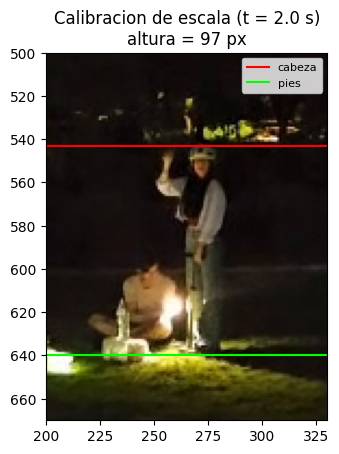

In [4]:
frame_persona = obtener_frame(2.0)

cabeza_px = 543
pies_px = 640
altura_px = pies_px - cabeza_px
altura_m = 1.60

escala = altura_m / altura_px
print(f"Altura de la persona: {altura_px} px")
print(f"Escala: {escala:.5f} m/px")

fig, ax = plt.subplots(figsize=(3.5, 5))
ax.imshow(frame_persona)
ax.axhline(cabeza_px, color="red", lw=1.5, label="cabeza")
ax.axhline(pies_px, color="lime", lw=1.5, label="pies")
ax.set_xlim(200, 330)
ax.set_ylim(670, 500)
ax.legend(fontsize=8, loc="upper right")
ax.set_title(f"Calibracion de escala (t = 2.0 s)\naltura = {altura_px} px")
plt.tight_layout()
plt.show()

### 1.3 Posiciones del cohete (medidas a mano)

In [5]:
def candidatos_blancos(frame_rgb, caja, s_max=60, v_min=175):
    x0, x1, y0, y1 = caja
    recorte_bgr = cv2.cvtColor(frame_rgb[y0:y1, x0:x1], cv2.COLOR_RGB2BGR)
    hsv = cv2.cvtColor(recorte_bgr, cv2.COLOR_BGR2HSV)
    saturacion = hsv[:, :, 1]
    brillo = hsv[:, :, 2]
    mascara = ((saturacion < s_max) & (brillo >= v_min)).astype(np.uint8) * 255

    n_manchas, _, stats, centroides = cv2.connectedComponentsWithStats(mascara, connectivity=8)
    candidatos = []
    for k in range(1, n_manchas):
        x, y, w, h, area = stats[k]
        if area < 4:
            continue
        if area / (w * h) < 0.15:
            continue
        candidatos.append((centroides[k][0] + x0, centroides[k][1] + y0, area))
    return candidatos


def trackear(caja, t_visibles, semilla_xy, semilla_v, s_max=60, v_min=175):
    dt = 1.0 / FPS
    x_prev, y_prev = semilla_xy
    vx_prev, vy_prev = semilla_v
    col_px, fila_px = [x_prev], [y_prev]

    for t in t_visibles[1:]:
        candidatos = candidatos_blancos(obtener_frame(t), caja, s_max=s_max, v_min=v_min)
        col_pred = x_prev + vx_prev * dt
        fila_pred = y_prev + vy_prev * dt
        distancias = [(c[0] - col_pred) ** 2 + (c[1] - fila_pred) ** 2 for c in candidatos]
        mejor = candidatos[int(np.argmin(distancias))]
        vx_prev = (mejor[0] - x_prev) / dt
        vy_prev = (mejor[1] - y_prev) / dt
        x_prev, y_prev = mejor[0], mejor[1]
        col_px.append(x_prev)
        fila_px.append(y_prev)

    return np.array(col_px), np.array(fila_px)

In [6]:
datos = [
    (667, 200, 159, 30.1), (668, 200, 137, 30.9),
    (672, 201,  61, 32.0), (673, 203,  43, 33.0),
    (708, 240,  57, 41.1), (709, 238,  76, 41.1), (710, 238,  94, 41.0),
    (711, 238, 113, 40.8),
    (712, 238, 131, 40.5), (713, 238, 150, 40.4),
    (718, 242, 275, 40.2), (719, 244, 292, 40.0), (720, 244, 313, 39.8), (721, 246, 336, 39.6),
]

cuadro = np.array([d[0] for d in datos])
col_px = np.array([d[1] for d in datos], float)
fila_px = np.array([d[2] for d in datos], float)
dy_cam = np.array([d[3] for d in datos], float)
t_visibles = cuadro / FPS

print(pd.DataFrame({"t (s)": t_visibles.round(3), "columna (px)": col_px, "fila (px)": fila_px}).to_string(index=False))

 t (s)  columna (px)  fila (px)
22.242         200.0      159.0
22.275         200.0      137.0
22.409         201.0       61.0
22.442         203.0       43.0
23.609         240.0       57.0
23.642         238.0       76.0
23.676         238.0       94.0
23.709         238.0      113.0
23.743         238.0      131.0
23.776         238.0      150.0
23.943         242.0      275.0
23.976         244.0      292.0
24.009         244.0      313.0
24.043         246.0      336.0


In [7]:
def imprimir_datos(cuadros, col_px, fila_px, dy_cam, por_linea=2):
    filas = [f"({k}, {c:5.1f}, {f:5.1f}, {d:4.1f})" for k, c, f, d in zip(cuadros, col_px, fila_px, dy_cam)]
    print("datos = [")
    for i in range(0, len(filas), por_linea):
        print("    " + ", ".join(filas[i:i + por_linea]) + ",")
    print("]")


caja = (0, ANCHO, 0, ALTO)
cuadros = np.array([d[0] for d in datos])
inicios = np.r_[0, np.where(np.diff(cuadros) > 1)[0] + 1, len(cuadros)]

col_det, fila_det = [], []
for a, b in zip(inicios[:-1], inicios[1:]):
    dt = (cuadros[a + 1] - cuadros[a]) / FPS
    semilla_xy = (col_px[a], fila_px[a])
    semilla_v = ((col_px[a + 1] - col_px[a]) / dt, (fila_px[a + 1] - fila_px[a]) / dt)
    col, fila = trackear(caja, cuadros[a:b] / FPS, semilla_xy, semilla_v)
    col_det += list(col)
    fila_det += list(fila)

imprimir_datos(cuadros, col_det, fila_det, dy_cam)
print(f"\nDiferencia maxima con 'datos': {np.abs(np.array(col_det) - col_px).max():.1f} px en columna, "
      f"{np.abs(np.array(fila_det) - fila_px).max():.1f} px en fila")

datos = [
    (667, 200.0, 159.0, 30.1), (668, 217.1, 465.9, 30.9),
    (672, 201.0,  61.0, 32.0), (673, 209.6, 467.8, 33.0),
    (708, 240.0,  57.0, 41.1), (709, 211.9, 476.2, 41.1),
    (710, 150.9, 686.2, 41.0), (711, 150.8, 686.0, 40.8),
    (712, 150.7, 686.0, 40.5), (713, 150.6, 685.9, 40.4),
    (718, 242.0, 275.0, 40.2), (719, 211.0, 475.4, 40.0),
    (720, 182.9, 677.3, 39.8), (721, 149.7, 685.0, 39.6),
]

Diferencia maxima con 'datos': 96.3 px en columna, 592.2 px en fila


Verificación visual.

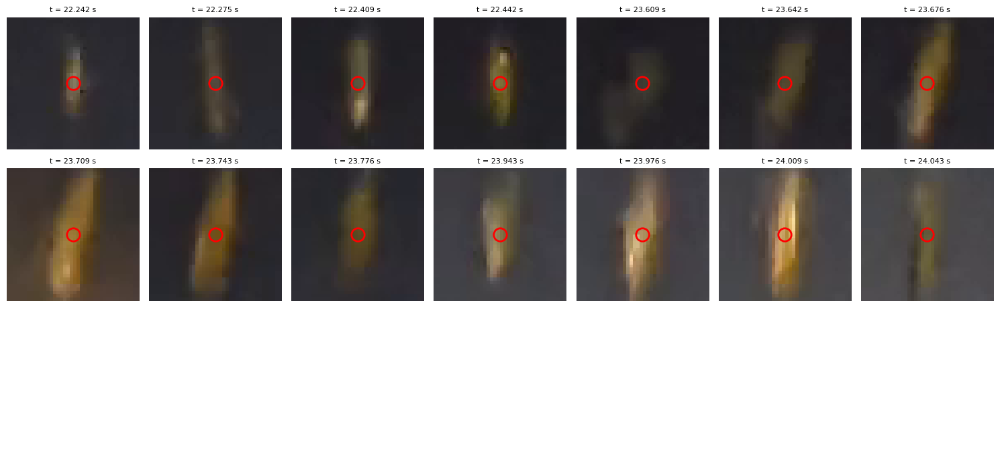

In [8]:
fig, axs = plt.subplots(3, 7, figsize=(15, 7))
axs = axs.reshape(-1)
for ax, t, xc, yc in zip(axs, t_visibles, col_px, fila_px):
    x0, y0 = int(xc - 20), int(yc - 20)
    ax.imshow(obtener_frame(t)[y0:y0 + 40, x0:x0 + 40], extent=[x0, x0 + 40, y0 + 40, y0])
    ax.plot(xc, yc, "o", mfc="none", mec="red", ms=14, mew=2)
    ax.set_title(f"t = {t:.3f} s", fontsize=8)
    ax.axis("off")
for ax in axs[len(t_visibles):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 1.4 Pasando a unidades físicas

In [9]:
t_rel = t_visibles - t_visibles[0]
n = len(t_rel)

y_lineal = (pies_px - (fila_px - dy_cam)) * escala

D_cam, h_cam = 18.0, 1.71
f_px = D_cam / escala
cy = ALTO / 2
inclinacion0 = np.arctan((pies_px - cy) / f_px) - np.arctan(h_cam / D_cam)
elevacion = inclinacion0 + np.arctan((cy - (fila_px - dy_cam)) / f_px)
y_m = h_cam + D_cam * np.tan(elevacion)
x_m = col_px * escala

print(f"Inclinacion de la camara en t = 2 s: {np.degrees(inclinacion0):.1f} grados")
print(f"Distancia focal equivalente: {f_px:.0f} px\n")

paso_normal = 1.0 / FPS
nuevo_tramo = np.r_[True, np.diff(t_visibles) > 3 * paso_normal]
id_tramo = np.cumsum(nuevo_tramo)


def derivada(t, x):
    v = np.zeros(len(t))
    v[1:-1] = (x[2:] - x[:-2]) / (t[2:] - t[:-2])
    v[0] = (x[1] - x[0]) / (t[1] - t[0])
    v[-1] = (x[-1] - x[-2]) / (t[-1] - t[-2])
    return v


vx = np.full(n, np.nan)
vy = np.full(n, np.nan)
ay = np.full(n, np.nan)

for tramo in np.unique(id_tramo):
    idx = np.where(id_tramo == tramo)[0]
    if len(idx) < 2:
        continue
    vx[idx] = derivada(t_rel[idx], x_m[idx])
    vy[idx] = derivada(t_rel[idx], y_m[idx])
    if len(idx) >= 3:
        y = y_m[idx]
        ay[idx[1:-1]] = (y[2:] - 2 * y[1:-1] + y[:-2]) / paso_normal ** 2

tabla = pd.DataFrame({
    "tramo": id_tramo, "t (s)": t_rel.round(3), "x (m)": x_m.round(2), "y (m)": y_m.round(2),
    "vx (m/s)": vx.round(2), "vy (m/s)": vy.round(2), "ay (m/s2)": ay.round(1),
})
print(tabla.to_string())

Inclinacion de la camara en t = 2 s: 5.7 grados
Distancia focal equivalente: 1091 px

    tramo  t (s)  x (m)  y (m)  vx (m/s)  vy (m/s)  ay (m/s2)
0       1  0.000   3.30   8.58      0.00     12.06        NaN
1       1  0.033   3.30   8.99      0.00     12.06        NaN
2       2  0.167   3.32  10.36      0.99     10.24        NaN
3       2  0.200   3.35  10.70      0.99     10.24        NaN
4       3  1.367   3.96  10.59     -0.99    -10.23        NaN
5       3  1.401   3.93  10.25     -0.49     -9.97       15.6
6       3  1.434   3.93   9.93      0.00     -9.99      -16.6
7       3  1.467   3.93   9.59      0.00    -10.01       15.5
8       3  1.501   3.93   9.26      0.00     -9.94      -11.7
9       3  1.534   3.93   8.92      0.00    -10.14        NaN
10      4  1.701   3.99   6.74      0.99     -8.89        NaN
11      4  1.734   4.02   6.44      0.49     -9.90      -60.8
12      4  1.767   4.02   6.08      0.49    -11.40      -29.4
13      4  1.801   4.06   5.68      0.99    -1

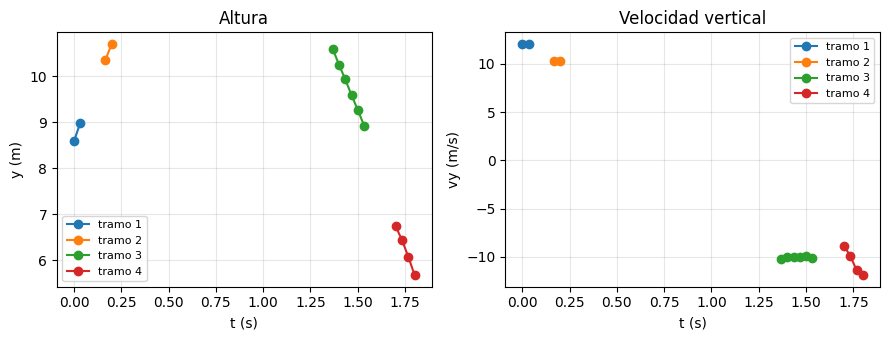

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for tramo in np.unique(id_tramo):
    idx = id_tramo == tramo
    ax[0].plot(t_rel[idx], y_m[idx], "o-", label=f"tramo {tramo}")
    ax[1].plot(t_rel[idx], vy[idx], "o-", label=f"tramo {tramo}")
ax[0].set_ylabel("y (m)")
ax[0].set_title("Altura")
ax[1].set_ylabel("vy (m/s)")
ax[1].set_title("Velocidad vertical")
for a in ax:
    a.set_xlabel("t (s)")
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1.4b Estimación del tramo fuera de cuadro (movimiento parabólico)

El apogeo no se ve en el video (el cohete sale por el borde superior). Se ajusta una parábola y(t) = y0 + v0*t + a*t^2/2 a los puntos medidos para estimar el apogeo y las velocidades fuera de cuadro.

- Modelo A: parábola libre (la aceleración sale del ajuste e incluye, de forma aproximada, el arrastre).
- Modelo B: parábola ideal con g = 9.81 m/s2 fijo.

Si la gravedad efectiva del modelo A se aleja mucho de 9.81, los datos no calzan con una parábola ideal y conviene tomar el apogeo como un rango.

Borde superior del cuadro: 11.6 m sobre el suelo

Modelo A: parabola libre (mejor ajuste)
   Apogeo: 13.02 m sobre el suelo, a t = 0.78 s (t = 0 es el primer punto medido)
   Gravedad efectiva: 14.4 m/s2
   Velocidad de subida en t = 0: 11.2 m/s
   Error RMS del ajuste: 0.08 m
   Fuera de cuadro (estimado): de 0.33 s a 1.23 s (0.90 s)
   Fuera de cuadro (medido): de 0.20 s a 1.37 s
   Velocidad al salir: 6.5 m/s hacia arriba; al volver: 6.5 m/s hacia abajo

Modelo B: parabola ideal, g = 9.81 m/s2
   Apogeo: 11.81 m sobre el suelo, a t = 0.74 s (t = 0 es el primer punto medido)
   Gravedad efectiva: 9.8 m/s2
   Velocidad de subida en t = 0: 7.3 m/s
   Error RMS del ajuste: 0.47 m
   Fuera de cuadro (estimado): de 0.52 s a 0.96 s (0.45 s)
   Fuera de cuadro (medido): de 0.20 s a 1.37 s
   Velocidad al salir: 2.2 m/s hacia arriba; al volver: 2.2 m/s hacia abajo

Resumen: apogeo estimado entre 11.8 y 13.0 m sobre el suelo (modelo A: 13.0 m).


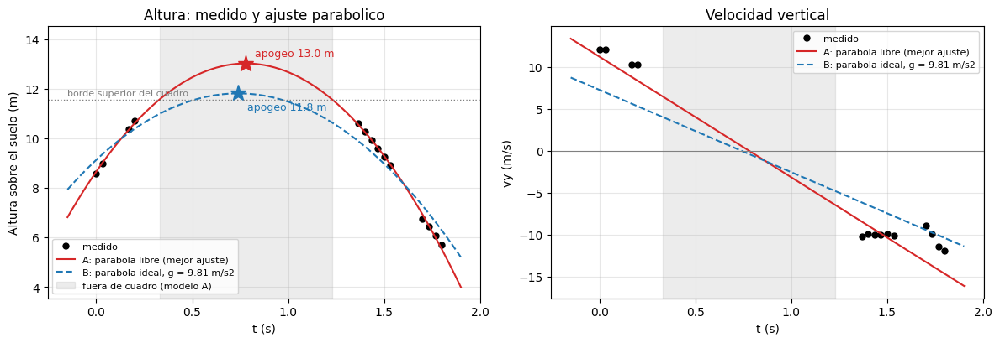

In [11]:
def ajustar_parabola(t, y, g_fijo=None):
    if g_fijo is None:
        c2, c1, c0 = np.polyfit(t, y, 2)
        return c0, c1, 2 * c2
    A = np.c_[np.ones_like(t), t]
    (y0, v0), *_ = np.linalg.lstsq(A, y + 0.5 * g_fijo * t ** 2, rcond=None)
    return y0, v0, -g_fijo


def altura(p, t):
    return p[0] + p[1] * t + 0.5 * p[2] * t ** 2


def velocidad(p, t):
    return p[1] + p[2] * t


def tiempos_fuera_de_cuadro(p):
    y0, v0, a = p
    disc = v0 ** 2 - 2 * a * (y0 - y_borde)
    if disc < 0:
        return None
    return sorted([(-v0 + s * np.sqrt(disc)) / a for s in (1, -1)])


elev_borde = inclinacion0 + np.arctan((cy + dy_cam.mean()) / f_px)
y_borde = h_cam + D_cam * np.tan(elev_borde)

modelos = [
    ("A: parabola libre (mejor ajuste)", ajustar_parabola(t_rel, y_m), "tab:red", "-"),
    ("B: parabola ideal, g = 9.81 m/s2", ajustar_parabola(t_rel, y_m, g_fijo=g), "tab:blue", "--"),
]

print(f"Borde superior del cuadro: {y_borde:.1f} m sobre el suelo\n")
apogeos = []
for nombre, p, _, _ in modelos:
    t_ap = -p[1] / p[2]
    y_ap = altura(p, t_ap)
    rms = np.sqrt(np.mean((y_m - altura(p, t_rel)) ** 2))
    apogeos.append((y_ap, t_ap))
    print(f"Modelo {nombre}")
    print(f"   Apogeo: {y_ap:.2f} m sobre el suelo, a t = {t_ap:.2f} s (t = 0 es el primer punto medido)")
    print(f"   Gravedad efectiva: {-p[2]:.1f} m/s2")
    print(f"   Velocidad de subida en t = 0: {p[1]:.1f} m/s")
    print(f"   Error RMS del ajuste: {rms:.2f} m")
    cruces = tiempos_fuera_de_cuadro(p)
    if y_ap > y_borde and cruces:
        t1, t2 = cruces
        print(f"   Fuera de cuadro (estimado): de {t1:.2f} s a {t2:.2f} s ({t2 - t1:.2f} s)")
        print(f"   Fuera de cuadro (medido): de {t_rel[3]:.2f} s a {t_rel[4]:.2f} s")
        print(f"   Velocidad al salir: {abs(velocidad(p, t1)):.1f} m/s hacia arriba; "
              f"al volver: {abs(velocidad(p, t2)):.1f} m/s hacia abajo")
    print()

ya = [a[0] for a in apogeos]
print(f"Resumen: apogeo estimado entre {min(ya):.1f} y {max(ya):.1f} m sobre el suelo "
      f"(modelo A: {ya[0]:.1f} m).")

t_plot = np.linspace(t_rel[0] - 0.15, t_rel[-1] + 0.1, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

for tramo in np.unique(id_tramo):
    idx = id_tramo == tramo
    etiqueta = "medido" if tramo == 1 else None
    ax[0].plot(t_rel[idx], y_m[idx], "ko", ms=5, label=etiqueta)
    ax[1].plot(t_rel[idx], vy[idx], "ko", ms=5, label=etiqueta)

for (nombre, p, color, estilo), (y_ap, t_ap) in zip(modelos, apogeos):
    ax[0].plot(t_plot, altura(p, t_plot), estilo, color=color, label=nombre)
    ax[1].plot(t_plot, velocidad(p, t_plot), estilo, color=color, label=nombre)
    ax[0].plot(t_ap, y_ap, "*", color=color, ms=14)
    ax[0].annotate(f"apogeo {y_ap:.1f} m", (t_ap, y_ap), textcoords="offset points",
                   xytext=(8, 6 if nombre[0] == "A" else -14), color=color, fontsize=9)

ax[0].set_ylim(top=max(ya) + 1.5)
ax[0].axhline(y_borde, color="gray", ls=":", lw=1)
ax[0].text(t_plot[0], y_borde + 0.15, "borde superior del cuadro", color="gray", fontsize=8)
cruces_A = tiempos_fuera_de_cuadro(modelos[0][1])
if cruces_A:
    ax[0].axvspan(*cruces_A, color="gray", alpha=0.15, label="fuera de cuadro (modelo A)")
    ax[1].axvspan(*cruces_A, color="gray", alpha=0.15)
ax[0].set_ylabel("Altura sobre el suelo (m)")
ax[0].set_title("Altura: medido y ajuste parabolico")
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_ylabel("vy (m/s)")
ax[1].set_title("Velocidad vertical")
for a in ax:
    a.set_xlabel("t (s)")
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 1.5 Exportar a Excel

In [12]:
df_exp = pd.DataFrame({
    "t": np.round(t_rel, 4),
    "y": np.round(y_m, 3),
    "y_lineal": np.round(y_lineal, 3),
    "vy": np.round(vy, 2),
    "ay": np.round(ay, 1),
    "step": np.arange(n),
    "tramo": id_tramo,
})
df_exp.to_excel("Dato_exp_l1.xlsx", index=False)
df_exp

,t,y,y_lineal,vy,ay,step,tramo
0,0.0000,8.584,8.431,12.06,NaN,0,1
1,0.0333,8.986,8.807,12.06,NaN,1,1
2,0.1667,10.359,10.078,10.24,NaN,2,2
3,0.2001,10.700,10.392,10.24,NaN,3,2
4,1.3672,10.594,10.294,-10.23,NaN,4,3
5,1.4005,10.253,9.981,-9.97,15.6,5,3
6,1.4339,9.929,9.682,-9.99,-16.6,6,3
7,1.4672,9.587,9.366,-10.01,15.5,7,3
8,1.5006,9.262,9.064,-9.94,-11.7,8,3
9,1.5339,8.924,8.749,-10.14,NaN,9,3


### 1.6 Coeficiente convectivo h y parámetros del lanzamiento

Usa los datos del informe, las posiciones medidas en el video y el apogeo medido (13 m).

In [13]:
P0_man = 4.0e5
P_atm = 101700.0
T_amb = 289.15
V_b = 1.5e-3
phi = 1 / 3
V_w0 = phi * V_b
V_a0 = V_b - V_w0
m_seca = 0.054
D_b = 0.075
D_g = 0.024
L_ref = 0.45
Cd_n = 0.90
CD_teo = 0.325
R_aire, gam = 287.0, 1.403
cv = R_aire / (gam - 1)
cp = gam * cv
rho_w, rho_a = 1000.0, 1.226
nu_a, k_a, Pr = 14.7e-6, 0.02525, 0.714
e_PET, k_PET = 0.25e-3, 0.30

H_lanz = 1.60
Y_APO = 13.0

A_f = np.pi * D_b ** 2 / 4
A_n = np.pi * D_g ** 2 / 4

P_MIN, P_MAX = 0.05e5, 3.0e5

integrar = getattr(np, "trapezoid", None) or np.trapz


def h_int_corr(T, T_pared, L):
    Tf = 0.5 * (T + T_pared)
    k = 0.0241 * (Tf / 273.15) ** 0.81
    mu = 1.716e-5 * (Tf / 273.15) ** 1.5 * (273.15 + 110.4) / (Tf + 110.4)
    rho = P_atm / (R_aire * Tf)
    nu = mu / rho
    alfa = k / (rho * cp)
    Ra = g * (1 / Tf) * max(abs(T_pared - T), 0.05) * L ** 3 / (nu * alfa)
    Pr_ = nu / alfa
    Nu = (0.825 + 0.387 * Ra ** (1 / 6) / (1 + (0.492 / Pr_) ** (9 / 16)) ** (8 / 27)) ** 2
    return Nu * k / L, Nu, Ra


def area_int(Va):
    L = Va / A_f
    return np.pi * D_b * L + A_f, L


def simular(CD, h_i="corr", P0m=P0_man, paso=2e-4, rt=1e-9):
    P0 = P0m + P_atm
    m_a0 = P0 * V_a0 / (R_aire * T_amb)
    T_pared = T_amb

    def calor_pared(T, Va):
        area, L = area_int(Va)
        if h_i == "corr":
            h, Nu, Ra = h_int_corr(T, T_pared, L)
        else:
            h, Nu, Ra = float(h_i), np.nan, np.nan
        return h, area, Nu, Ra

    def arrastre(m):
        return 0.5 * rho_a * CD * A_f / m

    def fase_agua(t, s):
        y, v, Va, T = s
        m_agua = rho_w * (V_b - Va)
        P = m_a0 * R_aire * T / Va
        u = np.sqrt(max(2 * (P - P_atm) / rho_w, 0))
        Qw = Cd_n * A_n * u
        m = m_seca + m_agua + m_a0
        h, A, _, _ = calor_pared(T, Va)
        return [v,
                rho_w * Qw * u / m - arrastre(m) * v * abs(v) - g,
                Qw,
                (-P * Qw + h * A * (T_pared - T)) / (m_a0 * cv)]

    def sin_agua(t, s):
        return s[2] - V_b + 1e-9
    sin_agua.terminal = True

    s1 = solve_ivp(fase_agua, [0, 2], [H_lanz, 0, V_a0, T_amb], events=sin_agua,
                   max_step=paso, rtol=rt, atol=1e-11)
    t1 = s1.t[-1]
    y1, v1, _, T1 = s1.y[:, -1]

    crit = (2 / (gam + 1)) ** (gam / (gam - 1))

    def fase_aire(t, s):
        y, v, ma, T = s
        P = ma * R_aire * T / V_b
        r = P / P_atm
        if r <= 1.0001:
            return [v, -g, 0, 0]
        if 1 / r < crit:
            md = Cd_n * A_n * P * np.sqrt(gam / (R_aire * T)) * (2 / (gam + 1)) ** ((gam + 1) / (2 * (gam - 1)))
            Pe = P * crit
            ve = np.sqrt(gam * R_aire * T * 2 / (gam + 1))
        else:
            Te = T * (1 / r) ** ((gam - 1) / gam)
            ve = np.sqrt(2 * cp * (T - Te))
            md = Cd_n * A_n * (P_atm / (R_aire * Te)) * ve
            Pe = P_atm
        m = m_seca + ma
        h, _, _, _ = calor_pared(T, V_b)
        A = np.pi * D_b * (V_b / A_f) + 2 * A_f
        empuje = md * ve + (Pe - P_atm) * A_n
        return [v,
                empuje / m - arrastre(m) * v * abs(v) - g,
                -md,
                (-md * R_aire * T + h * A * (T_pared - T)) / (ma * cv)]

    def sin_presion(t, s):
        return s[2] * R_aire * s[3] / V_b - P_atm * 1.0001
    sin_presion.terminal = True

    s2 = solve_ivp(fase_aire, [t1, t1 + 1], [y1, v1, m_a0, T1], events=sin_presion,
                   max_step=paso, rtol=rt, atol=1e-12)
    t2 = s2.t[-1]
    y2, v2, ma2, _ = s2.y[:, -1]

    m3 = m_seca + ma2

    def vuelo(t, s):
        return [s[1], -g - arrastre(m3) * s[1] * abs(s[1])]

    def en_el_suelo(t, s):
        return s[0]
    en_el_suelo.terminal = True

    s3 = solve_ivp(vuelo, [t2, t2 + 30], [y2, v2], events=en_el_suelo,
                   max_step=10 * paso, rtol=rt)

    return dict(s1=s1, s2=s2, s3=s3, t1=t1, t2=t2, m_a0=m_a0, P0=P0,
                calor_pared=calor_pared, fase_aire=fase_aire, arrastre=arrastre,
                y_apo=max(s.y[0].max() for s in (s1, s2, s3)))

In [14]:
def mostrar(df):
    print(df.to_string(index=False))


Rv = simular(CD_teo, 0)
v_max_val = max(Rv["s1"].y[1].max(), Rv["s2"].y[1].max())
print("Validacion con el informe (CD = 0.325, sin intercambio de calor)")
mostrar(pd.DataFrame({
    "Variable": ["Apogeo sobre la salida (m)", "Fin del agua (ms)", "Fin del empuje (ms)", "Velocidad maxima (m/s)"],
    "Modelo": [round(Rv["y_apo"] - H_lanz, 2), round(Rv["t1"] * 1e3, 2), round(Rv["t2"] * 1e3, 2), round(v_max_val, 2)],
    "Informe": [63.48, 53.48, 73.69, 60.07],
}))


def trayectoria(P0m, CD):
    R_ = simular(CD, "corr", P0m=P0m, paso=1e-3, rt=1e-6)
    t = np.r_[R_["s1"].t, R_["s2"].t, R_["s3"].t]
    y = np.r_[R_["s1"].y[0], R_["s2"].y[0], R_["s3"].y[0]]
    return t, y


def residuos_video(p, CD):
    P0m, desfase = p
    t, y = trayectoria(P0m, CD)
    i = y.argmax()
    res = []
    for tt, yy in zip(t_rel + desfase, y_m):
        if tt <= t[i]:
            y_modelo = np.interp(tt, t[:i + 1], y[:i + 1])
        else:
            y_modelo = np.interp(tt, t[i:], y[i:])
        res.append(y_modelo - yy)
    res.append(y.max() - Y_APO)
    return np.array(res)


def ajustar(CD, x0, con_apogeo=True):
    if con_apogeo:
        f = lambda p: residuos_video(p, CD)
    else:
        f = lambda p: residuos_video(p, CD)[:-1]
    return least_squares(f, x0, bounds=([P_MIN, 0], [P_MAX, 1.5]), diff_step=1e-2, max_nfev=40)


def rms_posiciones(ajuste, con_apogeo=True):
    errores = ajuste.fun[:-1] if con_apogeo else ajuste.fun
    return np.sqrt(np.mean(errores ** 2))


def presion_para_apogeo(CD):
    return brentq(lambda P: simular(CD, "corr", P0m=P, paso=1e-3, rt=1e-6)["y_apo"] - Y_APO,
                  P_MIN, P_MAX, xtol=5)


def mostrar_apogeo_vs_presion():
    presiones = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
    print("\nApogeo segun la presion (CD = 0.325)")
    mostrar(pd.DataFrame({
        "Presion (bar)": presiones,
        "Apogeo (m)": [round(simular(CD_teo, "corr", P0m=Pb * 1e5, paso=1e-3, rt=1e-6)["y_apo"], 1)
                       for Pb in presiones],
    }))

Validacion con el informe (CD = 0.325, sin intercambio de calor)
                  Variable  Modelo  Informe
Apogeo sobre la salida (m)   63.39    63.48
         Fin del agua (ms)   53.51    53.48
       Fin del empuje (ms)   74.07    73.69
    Velocidad maxima (m/s)   59.98    60.07


In [15]:
def analizar(P0_cal, apogeo_energia=None):
    R = simular(CD_teo, "corr", P0m=P0_cal)
    s1, s2, s3, t1, t2 = R["s1"], R["s2"], R["s3"], R["t1"], R["t2"]

    t_t = np.r_[s1.t, s2.t]
    T_t = np.r_[s1.y[3], s2.y[3]]
    Va_t = np.r_[s1.y[2], np.full(len(s2.t), V_b)]
    h_t, _, Nu_t, Ra_t = np.array([R["calor_pared"](T, Va) for T, Va in zip(T_t, Va_t)]).T

    h_i_medio = integrar(h_t, t_t) / (t_t[-1] - t_t[0])
    A_i0 = area_int(V_a0)[0]
    tau_corr = R["m_a0"] * cv / (h_i_medio * A_i0)

    print("\nCoeficiente convectivo interno (correlacion de conveccion natural)")
    print(f"   h interno medio: {h_i_medio:.1f} W/m2K (minimo {h_t.min():.1f}, maximo {h_t.max():.1f})")
    print(f"   Nusselt medio: {np.nanmean(Nu_t):.0f}")
    print(f"   Rayleigh medio: {np.nanmean(Ra_t):.1e}")
    print(f"   Biot interno: {h_i_medio * e_PET / k_PET:.1e}")
    print(f"   Tiempo termico: {tau_corr:.2f} s; tiempo de empuje: {t2 * 1e3:.0f} ms (razon {t2 / tau_corr:.3f})")
    print("   Durante el empuje el flujo es muy transitorio: la correlacion natural es una cota inferior.")

    print(f"\nBarrido de h interno (CD = {CD_teo}, presion = {P0_cal / 1e5:.2f} bar)")
    filas = []
    for hi in [0, 10, 30, 100, 1000, 5000]:
        Rh = simular(CD_teo, hi, P0m=P0_cal)
        sa, sb = Rh["s1"], Rh["s2"]
        tau = np.inf if hi == 0 else Rh["m_a0"] * cv / (hi * A_i0)
        P_fin = Rh["m_a0"] * R_aire * sa.y[3][-1] / sa.y[2][-1]
        filas.append({
            "h interno (W/m2K)": hi,
            "Tiempo termico (s)": round(tau, 4),
            "Empuje / tiempo termico": round(Rh["t2"] / tau, 3),
            "Apogeo (m)": round(Rh["y_apo"], 2),
            "T minima (C)": round(min(sa.y[3].min(), sb.y[3].min()) - 273.15, 1),
            "P fin del agua (kPa)": round(P_fin / 1e3, 1),
            "Biot": round(hi * e_PET / k_PET, 2),
        })
    mostrar(pd.DataFrame(filas))

    t_all = np.r_[s1.t, s2.t, s3.t]
    y_all = np.r_[s1.y[0], s2.y[0], s3.y[0]]
    v_all = np.r_[s1.y[1], s2.y[1], s3.y[1]]

    Re = np.abs(v_all) * L_ref / nu_a
    Nu_e = np.where(Re < 5e5, 0.664 * np.sqrt(Re) * Pr ** (1 / 3), (0.037 * Re ** 0.8 - 871) * Pr ** (1 / 3))
    h_ext = Nu_e * k_a / L_ref
    h_ext_medio = integrar(h_ext, t_all) / (t_all[-1] - t_all[0])

    print(f"\nCoeficiente convectivo externo (largo de referencia {L_ref} m)")
    print(f"   h externo maximo: {h_ext.max():.1f} W/m2K a los {t_all[h_ext.argmax()] * 1e3:.0f} ms")
    print(f"   h externo medio en todo el vuelo: {h_ext_medio:.1f} W/m2K")
    print(f"   Reynolds maximo: {Re.max():.2e}; Nusselt maximo: {Nu_e.max():.0f}; Biot externo: {h_ext.max() * e_PET / k_PET:.3f}")
    print("   Valores del informe: h externo maximo 148.7 W/m2K, Biot 0.122")

    P1 = R["m_a0"] * R_aire * s1.y[3] / s1.y[2]
    P2 = s2.y[2] * R_aire * s2.y[3] / V_b
    u_agua = np.sqrt(2 * (P1 - P_atm) / rho_w)
    F1 = rho_w * Cd_n * A_n * u_agua ** 2

    def empuje_aire(s):
        m = m_seca + s[2]
        return (R["fase_aire"](0, s)[1] + g) * m + R["arrastre"](m) * m * s[1] * abs(s[1])

    F2 = np.array([empuje_aire(s) for s in s2.y.T])
    impulso = integrar(F1, s1.t) + integrar(F2, s2.t)
    v_max = max(s1.y[1].max(), s2.y[1].max())
    i_ap = y_all.argmax()
    t_ap = t_all[i_ap]
    if apogeo_energia is None:
        apogeo_energia = y_all.max()
    E_isot = R["P0"] * V_a0 * np.log(R["P0"] / P_atm)
    E_pot = m_seca * g * (apogeo_energia - H_lanz)
    n_pol = np.log(P1[0] / P1[-1]) / np.log(s1.y[2][-1] / s1.y[2][0])
    masa_inicial = m_seca + rho_w * V_w0 + R["m_a0"]

    print(f"\nDinamica del empuje (presion {P0_cal / 1e5:.2f} bar, CD = {CD_teo})")
    print(f"   Masa inicial: {masa_inicial * 1e3:.0f} g (aire {R['m_a0'] * 1e3:.2f} g; informe 6.05 g)")
    print(f"   Fin del agua: {t1 * 1e3:.1f} ms; fin del empuje: {t2 * 1e3:.1f} ms")
    print(f"   Velocidad maxima de salida del agua: {u_agua.max():.1f} m/s")
    print(f"   Presion al fin del agua: {P1[-1] / 1e3:.0f} kPa")
    print(f"   Temperatura minima del aire: {T_t.min() - 273.15:.1f} C")
    print(f"   Exponente politropico: {n_pol:.3f}")
    print(f"   Empuje maximo: {max(F1.max(), F2.max()):.0f} N; impulso total: {impulso:.2f} N s")
    print(f"   Velocidad maxima: {v_max:.1f} m/s (Mach {v_max / 340.8:.3f})")
    print(f"   Apogeo: {y_all.max():.2f} m a los {t_ap:.2f} s")
    print(f"   Impacto: {abs(v_all[-1]):.1f} m/s a los {t_all[-1]:.2f} s")
    print(f"   Energia potencial ganada: {E_pot:.2f} J de {E_isot:.0f} J disponibles (rendimiento {100 * E_pot / E_isot:.1f} %)")
    print(f"   Con los 4 bar del informe, el mismo cohete subiria {Rv['y_apo']:.1f} m")

    i0 = np.argmax(y_all[:i_ap] >= y_m[0])
    t_en = t_all - t_all[i0]
    y_modelo = np.interp(t_rel, t_en[:i_ap + 1], y_all[:i_ap + 1])
    subida = id_tramo <= 2
    rms_sub = np.sqrt(np.mean((y_modelo[subida] - y_m[subida]) ** 2))

    print("\nComparacion con el video")
    print(f"   Velocidad de subida a {y_m[0]:.1f} m: modelo {np.interp(y_m[0], y_all[:i_ap], v_all[:i_ap]):.1f} m/s; video {vy[0]:.1f} m/s")
    print(f"   Velocidad de subida en el borde del cuadro ({y_borde:.1f} m): modelo {np.interp(y_borde, y_all[:i_ap], v_all[:i_ap]):.1f} m/s")
    print(f"   Error RMS en la subida medida: {rms_sub:.2f} m")

    fig, ax = plt.subplots(2, 2, figsize=(12, 7))
    ax = ax.ravel()
    ax[0].plot(t_en, y_all, "r-", label=f"modelo ({P0_cal / 1e5:.2f} bar, CD = {CD_teo})")
    ax[0].plot(t_rel, y_m, "ko", ms=4, label="video")
    ax[0].axhline(Y_APO, color="gray", ls=":")
    ax[0].set_xlim(-0.3, t_en.max())
    ax[0].set_xlabel("t (s), 0 = primer punto medido")
    ax[0].set_ylabel("y (m)")
    ax[0].set_title("Trayectoria")
    ax[0].legend(fontsize=8)
    ax[1].plot(t_t * 1e3, np.r_[P1, P2] / 1e3, "b-")
    ax[1].set_xlabel("t (ms)")
    ax[1].set_ylabel("P (kPa)")
    ax[1].set_title("Presion del aire durante el empuje")
    ax[2].plot(t_t * 1e3, h_t, "g-")
    ax[2].set_xlabel("t (ms)")
    ax[2].set_ylabel("h interno (W/m2K)")
    ax[2].set_title("h interno (correlacion)")
    ax[3].plot(t_all, h_ext, "m-")
    ax[3].set_xlabel("t (s)")
    ax[3].set_ylabel("h externo (W/m2K)")
    ax[3].set_title("h externo")
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

#### Escenario A: presión ajustada solo con el apogeo medido (13 m)

La presión se calcula para que el modelo llegue exactamente a 13 m. Se muestran también los ajustes con las posiciones del video, a modo de comparación.

Ajuste de la presion con el apogeo medido (13.0 m), rango medido 0.05 a 3 bar, CD = 0.325
   Solo apogeo (escenario A): 0.92 bar manometricos (1.94 bar absolutos)
   Solo posiciones del video: 0.88 bar (error RMS 0.50 m)
   Posiciones y apogeo: 0.89 bar (error RMS 0.51 m, desfase 0.76 s)

Sensibilidad al coeficiente de arrastre (rango del informe), apogeo = 13 m
   CD  Presion (bar)
0.217           0.91
0.325           0.92
0.450           0.95

Apogeo segun la presion (CD = 0.325)
 Presion (bar)  Apogeo (m)
           0.5         2.6
           1.0        15.1
           1.5        27.2
           2.0        37.0
           2.5        45.4
           3.0        52.7

Coeficiente convectivo interno (correlacion de conveccion natural)
   h interno medio: 4.9 W/m2K (minimo 0.9, maximo 6.0)
   Nusselt medio: 61
   Rayleigh medio: 1.3e+08
   Biot interno: 4.1e-03
   Tiempo termico: 5.89 s; tiempo de empuje: 156 ms (razon 0.026)
   Durante el empuje el flujo es muy transitorio: la correlaci

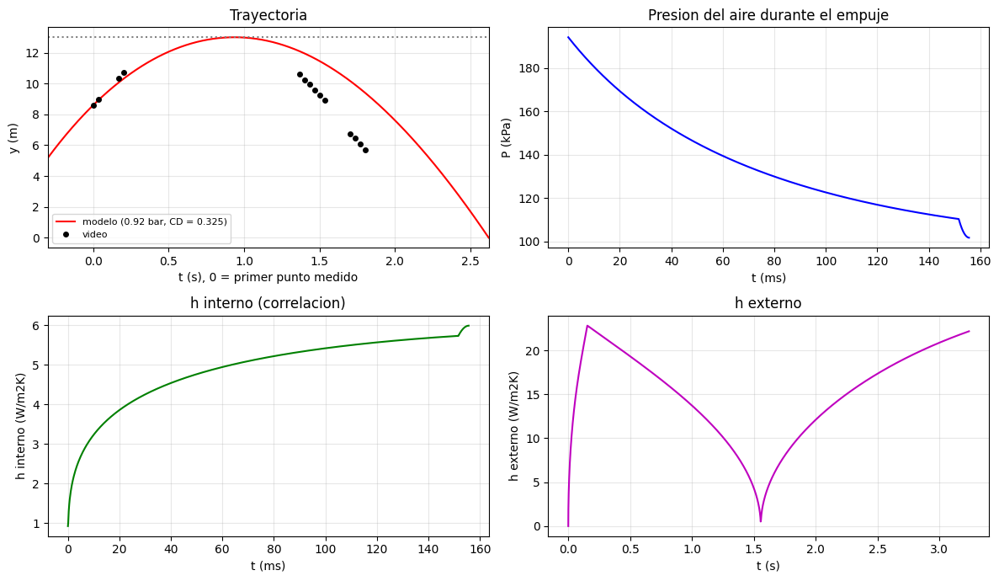

In [16]:
P_a = presion_para_apogeo(CD_teo)
solo_pos = ajustar(CD_teo, [P_a, 0.7], con_apogeo=False)
pos_y_apogeo = ajustar(CD_teo, [P_a, 0.7])

print(f"Ajuste de la presion con el apogeo medido ({Y_APO} m), rango medido 0.05 a 3 bar, CD = {CD_teo}")
print(f"   Solo apogeo (escenario A): {P_a / 1e5:.2f} bar manometricos ({(P_a + P_atm) / 1e5:.2f} bar absolutos)")
print(f"   Solo posiciones del video: {solo_pos.x[0] / 1e5:.2f} bar (error RMS {rms_posiciones(solo_pos, False):.2f} m)")
print(f"   Posiciones y apogeo: {pos_y_apogeo.x[0] / 1e5:.2f} bar "
      f"(error RMS {rms_posiciones(pos_y_apogeo):.2f} m, desfase {pos_y_apogeo.x[1]:.2f} s)")

print(f"\nSensibilidad al coeficiente de arrastre (rango del informe), apogeo = {Y_APO:.0f} m")
mostrar(pd.DataFrame({
    "CD": [0.217, 0.325, 0.450],
    "Presion (bar)": [round(presion_para_apogeo(cd) / 1e5, 2) for cd in [0.217, 0.325, 0.450]],
}))
mostrar_apogeo_vs_presion()

analizar(P_a, apogeo_energia=Y_APO)

#### Escenario B: presión ajustada con las posiciones del video y el apogeo

Ajusta la presión y un desfase temporal para que el modelo calce con los puntos medidos y con el apogeo.

Ajuste de la presion inicial (posiciones del video y apogeo medido)
   Presion manometrica: 0.89 bar (1.90 bar absolutos)
   Desfase temporal: 0.76 s
   Error RMS de posiciones: 0.51 m
   Apogeo del modelo: 11.90 m (medido: 13.0 m)

Sensibilidad al coeficiente de arrastre (rango del informe)
   CD  Presion (bar)  Error RMS (m)  Desfase (s)
0.217           0.87           0.50         0.77
0.325           0.89           0.51         0.76
0.450           0.90           0.52         0.75

Apogeo segun la presion (CD = 0.325)
 Presion (bar)  Apogeo (m)
           0.5         2.6
           1.0        15.1
           1.5        27.2
           2.0        37.0
           2.5        45.4
           3.0        52.7

Coeficiente convectivo interno (correlacion de conveccion natural)
   h interno medio: 4.9 W/m2K (minimo 0.9, maximo 5.9)
   Nusselt medio: 61
   Rayleigh medio: 1.3e+08
   Biot interno: 4.1e-03
   Tiempo termico: 5.76 s; tiempo de empuje: 164 ms (razon 0.028)
   Durante el empuje e

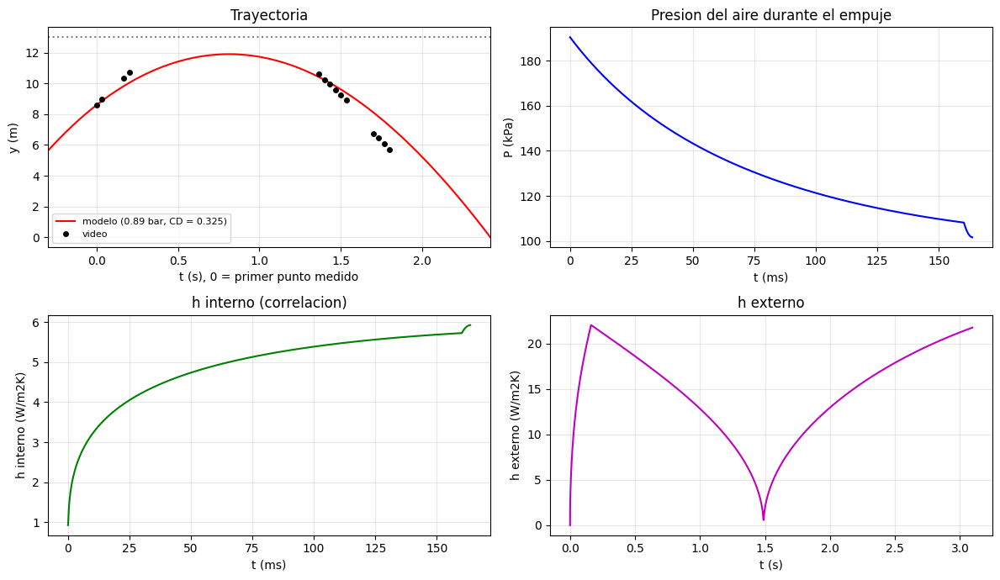

In [17]:
ajuste = ajustar(CD_teo, [presion_para_apogeo(CD_teo), 0.7])
P0_cal, desfase_cal = ajuste.x
apogeo_cal = simular(CD_teo, "corr", P0m=P0_cal, paso=1e-3, rt=1e-6)["y_apo"]

print("Ajuste de la presion inicial (posiciones del video y apogeo medido)")
print(f"   Presion manometrica: {P0_cal / 1e5:.2f} bar ({(P0_cal + P_atm) / 1e5:.2f} bar absolutos)")
print(f"   Desfase temporal: {desfase_cal:.2f} s")
print(f"   Error RMS de posiciones: {rms_posiciones(ajuste):.2f} m")
print(f"   Apogeo del modelo: {apogeo_cal:.2f} m (medido: {Y_APO} m)")

print("\nSensibilidad al coeficiente de arrastre (rango del informe)")
filas = []
for cd in [0.217, 0.325, 0.450]:
    aj = ajustar(cd, ajuste.x)
    filas.append({"CD": cd, "Presion (bar)": round(aj.x[0] / 1e5, 2),
                  "Error RMS (m)": round(rms_posiciones(aj), 2), "Desfase (s)": round(aj.x[1], 2)})
mostrar(pd.DataFrame(filas))
mostrar_apogeo_vs_presion()

analizar(P0_cal)

In [18]:
P_ATM_NUEVA = 101300.0
T_AMB_NUEVA = 25 + 273.15


def altura_maxima(presiones_bar, CD=CD_teo, h_i=0):
    global P_atm, T_amb, rho_a
    originales = (P_atm, T_amb, rho_a)
    P_atm, T_amb = P_ATM_NUEVA, T_AMB_NUEVA
    rho_a = P_atm / (R_aire * T_amb)
    try:
        filas = []
        for Pb in presiones_bar:
            R = simular(CD, h_i, P0m=Pb * 1e5, paso=1e-3, rt=1e-6)
            v_max = max(R["s1"].y[1].max(), R["s2"].y[1].max())
            filas.append({
                "Presion (bar)": Pb,
                "Apogeo sobre la salida (m)": round(R["y_apo"] - H_lanz, 2),
                "Apogeo sobre el suelo (m)": round(R["y_apo"], 2),
                "Velocidad maxima (m/s)": round(v_max, 1),
                "Fin del empuje (ms)": round(R["t2"] * 1e3, 1),
            })
        P_video = brentq(
            lambda P: simular(CD, h_i, P0m=P, paso=1e-3, rt=1e-6)["y_apo"] - Y_APO,
            P_MIN, P_MAX, xtol=5)
    finally:
        P_atm, T_amb, rho_a = originales
    return pd.DataFrame(filas), P_video


tabla, P_video = altura_maxima([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0])

print(f"P_atm = {P_ATM_NUEVA:.0f} Pa, T_amb = {T_AMB_NUEVA - 273.15:.0f} C, "
      f"densidad del aire = {P_ATM_NUEVA / (R_aire * T_AMB_NUEVA):.3f} kg/m3")
print(f"CD = {CD_teo}, sin intercambio de calor\n")
mostrar(tabla)
print(f"\nPresion para llegar al apogeo medido ({Y_APO:.0f} m): "
      f"{P_video / 1e5:.2f} bar manometricos")

P_atm = 101300 Pa, T_amb = 25 C, densidad del aire = 1.184 kg/m3
CD = 0.325, sin intercambio de calor

 Presion (bar)  Apogeo sobre la salida (m)  Apogeo sobre el suelo (m)  Velocidad maxima (m/s)  Fin del empuje (ms)
           0.5                        1.04                       2.64                     3.6               3000.0
           1.0                       13.57                      15.17                    17.1                143.4
           1.5                       25.84                      27.44                    26.7                107.0
           2.0                       35.88                      37.48                    34.5                 92.6
           2.5                       44.42                      46.02                    41.4                 84.6
           3.0                       51.89                      53.49                    47.9                 79.6
           4.0                       64.50                      66.10                    60.

In [19]:
P_ATM_NUEVA = 101300.0
T_AMB_NUEVA = 25 + 273.15
P_MODELO = 0.92e5


def presion_para(apogeo, CD, h_i="corr"):
    return brentq(lambda P: simular(CD, h_i, P0m=P, paso=1e-3, rt=1e-6)["y_apo"] - apogeo,
                  P_MIN, 12e5, xtol=5)


originales = (P_atm, T_amb, rho_a)
P_atm, T_amb = P_ATM_NUEVA, T_AMB_NUEVA
rho_a = P_atm / (R_aire * T_amb)
try:
    filas = []
    for cd in [0.217, 0.325, 0.450]:
        filas.append({
            "CD": cd,
            f"Presion para {Y_APO:.0f} m (bar)": round(presion_para(Y_APO, cd) / 1e5, 2),
            f"Apogeo del modelo a {P_MODELO / 1e5:.2f} bar (m)": round(
                simular(cd, "corr", P0m=P_MODELO, paso=1e-3, rt=1e-6)["y_apo"], 1),
        })
    tabla_modelo = pd.DataFrame(filas)
finally:
    P_atm, T_amb, rho_a = originales

print(f"P_atm = {P_ATM_NUEVA:.0f} Pa, T_amb = {T_AMB_NUEVA - 273.15:.0f} C "
      f"(densidad del aire {P_ATM_NUEVA / (R_aire * T_AMB_NUEVA):.3f} kg/m3)")
print("Segun el coeficiente de arrastre (con intercambio de calor)\n")
print(tabla_modelo.to_string(index=False))


CONDICIONES = {
    "informe (101700 Pa, 16 C)": dict(P_atm=101700.0, T_amb=289.15, rho_a=1.226),
    "ensayo (101300 Pa, 25 C)": dict(P_atm=P_ATM_NUEVA, T_amb=T_AMB_NUEVA, rho_a=P_ATM_NUEVA / (R_aire * T_AMB_NUEVA)),
}


def h_interno(cond, P0m, CD=CD_teo):
    global P_atm, T_amb, rho_a
    originales = (P_atm, T_amb, rho_a)
    P_atm, T_amb, rho_a = cond["P_atm"], cond["T_amb"], cond["rho_a"]
    try:
        R = simular(CD, "corr", P0m=P0m, paso=1e-3, rt=1e-6)
        s1, s2 = R["s1"], R["s2"]
        t_t = np.r_[s1.t, s2.t]
        T_t = np.r_[s1.y[3], s2.y[3]]
        Va_t = np.r_[s1.y[2], np.full(len(s2.t), V_b)]
        h_t, _, Nu_t, Ra_t = np.array([R["calor_pared"](T, Va) for T, Va in zip(T_t, Va_t)]).T
        h_medio = integrar(h_t, t_t) / (t_t[-1] - t_t[0])
        tau = R["m_a0"] * cv / (h_medio * area_int(V_a0)[0])
        return {"h medio (W/m2K)": round(h_medio, 2), "h min (W/m2K)": round(h_t.min(), 2),
                "h max (W/m2K)": round(h_t.max(), 2), "Nusselt medio": round(np.nanmean(Nu_t)),
                "Rayleigh medio": f"{np.nanmean(Ra_t):.2e}", "Biot interno": f"{h_medio * e_PET / k_PET:.2e}",
                "Tiempo termico (s)": round(tau, 2), "Tiempo de empuje (ms)": round(R["t2"] * 1e3, 1),
                "T minima aire (C)": round(T_t.min() - 273.15, 1), "Apogeo (m)": round(R["y_apo"], 2)}
    finally:
        P_atm, T_amb, rho_a = originales


print(f"\nh interno con la presion del modelo ({P_MODELO / 1e5:.2f} bar, CD = {CD_teo}), segun las condiciones ambientales\n")
tabla_h = pd.DataFrame({nombre: h_interno(cond, P_MODELO) for nombre, cond in CONDICIONES.items()})
print(tabla_h.to_string())

P_atm = 101300 Pa, T_amb = 25 C (densidad del aire 1.184 kg/m3)
Segun el coeficiente de arrastre (con intercambio de calor)

   CD  Presion para 13 m (bar)  Apogeo del modelo a 0.92 bar (m)
0.217                     0.90                              13.6
0.325                     0.92                              13.0
0.450                     0.94                              12.5

h interno con la presion del modelo (0.92 bar, CD = 0.325), segun las condiciones ambientales

                      informe (101700 Pa, 16 C) ensayo (101300 Pa, 25 C)
h medio (W/m2K)                            4.89                     4.84
h min (W/m2K)                              0.93                     0.92
h max (W/m2K)                              5.98                     5.92
Nusselt medio                                60                       58
Rayleigh medio                         1.29e+08                 1.14e+08
Biot interno                           4.08e-03                 4.04e-03
Tiempo t

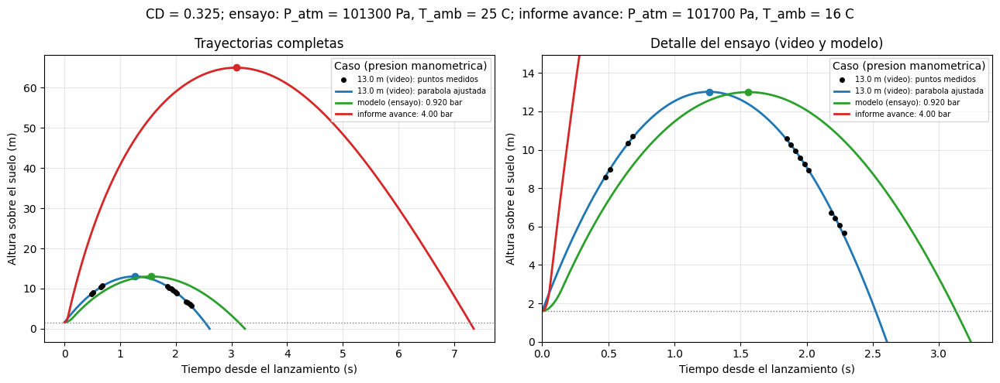

           Caso T amb (C) P atm (Pa) Presion (bar) Apogeo sobre la salida (m) Apogeo sobre el suelo (m) Velocidad maxima (m/s) Tiempo al apogeo (s) Tiempo de vuelo (s)
 13.0 m (video)        25     101300             -                       11.4                      13.0                      -                 1.26                2.61
modelo (ensayo)        25     101300         0.920                       11.4                      13.0                   15.3                 1.56                3.24
 informe avance        16     101700          4.00                       63.4                      65.0                   60.0                 3.08                7.35

Curva de 13 m: el lanzamiento (t = 0) ocurre 0.481 s antes del primer punto medido; apogeo 13.0 m a t = 1.26 s; aterriza a t = 2.61 s


In [20]:
from math import floor, log10


def cs(x, n=3):
    if x is None or x != x:
        return "-"
    dec = n - 1 - int(floor(log10(abs(x))))
    return f"{round(x, dec):.{max(dec, 0)}f}"


ENSAYO = dict(P_atm=101300.0, T_amb=25 + 273.15)
ENSAYO["rho_a"] = ENSAYO["P_atm"] / (R_aire * ENSAYO["T_amb"])
INFORME = dict(P_atm=101700.0, T_amb=289.15, rho_a=1.226)
P0_INFORME = 4.0e5
P_MODELO = 0.92e5


def simular_con(cond, P0m, CD, h_i):
    global P_atm, T_amb, rho_a
    originales = (P_atm, T_amb, rho_a)
    P_atm, T_amb, rho_a = cond["P_atm"], cond["T_amb"], cond["rho_a"]
    try:
        return simular(CD, h_i, P0m=P0m, paso=1e-3, rt=1e-6)
    finally:
        P_atm, T_amb, rho_a = originales


casos = [
    dict(nombre="modelo (ensayo)", cond=ENSAYO, P=P_MODELO, h_i="corr"),
    dict(nombre="informe avance", cond=INFORME, P=P0_INFORME, h_i=0),
]

for c in casos:
    R_ = simular_con(c["cond"], c["P"], CD_teo, c["h_i"])
    c["t"] = np.r_[R_["s1"].t, R_["s2"].t, R_["s3"].t]
    c["y"] = np.r_[R_["s1"].y[0], R_["s2"].y[0], R_["s3"].y[0]]
    c["y_apo"] = R_["y_apo"]
    c["t_ap"] = c["t"][c["y"].argmax()]
    c["t_fin"] = c["t"][-1]
    c["v_max"] = max(R_["s1"].y[1].max(), R_["s2"].y[1].max())

c2, c1, c0 = np.polyfit(t_rel, y_m, 2)
t_lanz = np.roots([c2, c1, c0 - H_lanz]).real.min()
t_suelo = np.roots([c2, c1, c0]).real.max()
t13 = np.linspace(t_lanz, t_suelo, 400)
y13 = np.polyval([c2, c1, c0], t13)
t_video = t_rel - t_lanz
casos.insert(0, dict(nombre="13.0 m (video)", cond=ENSAYO, P=np.nan, t=t13 - t_lanz, y=y13, y_apo=y13.max(),
                     t_ap=t13[y13.argmax()] - t_lanz, t_fin=t_suelo - t_lanz, v_max=np.nan))
c13 = casos[0]

colores = {"13.0 m (video)": "tab:blue", "modelo (ensayo)": "tab:green", "informe avance": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a in ax:
    a.plot(t_video, y_m, "ko", ms=4, label="13.0 m (video): puntos medidos", zorder=5)
    for c in casos:
        a.plot(c["t"], c["y"], color=colores[c["nombre"]], lw=2,
               label=(f"{c['nombre']}: parabola ajustada" if c is c13 else f"{c['nombre']}: {cs(c['P'] / 1e5)} bar"))
        a.plot(c["t_ap"], c["y_apo"], "o", color=colores[c["nombre"]], ms=6)

ax[0].set_title("Trayectorias completas")
ax[1].set_title("Detalle del ensayo (video y modelo)")
ax[1].set_xlim(0, max(c["t_fin"] for c in casos[:2]) * 1.05)
ax[1].set_ylim(0, casos[1]["y_apo"] * 1.15)
for a in ax:
    a.axhline(H_lanz, color="gray", ls=":", lw=1)
    a.set_xlabel("Tiempo desde el lanzamiento (s)")
    a.set_ylabel("Altura sobre el suelo (m)")
    a.grid(alpha=0.3)
    a.legend(title="Caso (presion manometrica)", fontsize=7)
fig.suptitle(f"CD = {CD_teo}; ensayo: P_atm = {ENSAYO['P_atm']:.0f} Pa, T_amb = {ENSAYO['T_amb'] - 273.15:.0f} C; "
             f"informe avance: P_atm = {INFORME['P_atm']:.0f} Pa, T_amb = {INFORME['T_amb'] - 273.15:.0f} C")
plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "Caso": [c["nombre"] for c in casos],
    "T amb (C)": [f"{c['cond']['T_amb'] - 273.15:.0f}" for c in casos],
    "P atm (Pa)": [f"{c['cond']['P_atm']:.0f}" for c in casos],
    "Presion (bar)": [cs(c["P"] / 1e5) for c in casos],
    "Apogeo sobre la salida (m)": [cs(c["y_apo"] - H_lanz) for c in casos],
    "Apogeo sobre el suelo (m)": [cs(c["y_apo"]) for c in casos],
    "Velocidad maxima (m/s)": [cs(c["v_max"]) for c in casos],
    "Tiempo al apogeo (s)": [cs(c["t_ap"]) for c in casos],
    "Tiempo de vuelo (s)": [cs(c["t_fin"]) for c in casos],
}).to_string(index=False))

print(f"\nCurva de 13 m: el lanzamiento (t = 0) ocurre {cs(-t_lanz)} s antes del primer punto medido; "
      f"apogeo {cs(c13['y_apo'])} m a t = {cs(c13['t_ap'])} s; aterriza a t = {cs(c13['t_fin'])} s")

In [21]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

g = 9.81

P0_man = 4.0e5
P_atm = 101700.0
T_amb = 289.15
V_b = 1.5e-3
phi = 1 / 3
V_w0 = phi * V_b
V_a0 = V_b - V_w0
m_seca = 0.054
D_b = 0.075
D_g = 0.024
L_ref = 0.45
Cd_n = 0.90
CD_teo = 0.325
R_aire, gam = 287.0, 1.403
cv = R_aire / (gam - 1)
cp = gam * cv
rho_w, rho_a = 1000.0, 1.226
nu_a, k_a, Pr = 14.7e-6, 0.02525, 0.714
e_PET, k_PET = 0.25e-3, 0.30

H_lanz = 1.60
Y_APO = 13.0

A_f = np.pi * D_b ** 2 / 4
A_n = np.pi * D_g ** 2 / 4

P_MIN, P_MAX = 0.05e5, 3.0e5

integrar = getattr(np, "trapezoid", None) or np.trapz


def h_int_corr(T, T_pared, L):
    Tf = 0.5 * (T + T_pared)
    k = 0.0241 * (Tf / 273.15) ** 0.81
    mu = 1.716e-5 * (Tf / 273.15) ** 1.5 * (273.15 + 110.4) / (Tf + 110.4)
    rho = P_atm / (R_aire * Tf)
    nu = mu / rho
    alfa = k / (rho * cp)
    Ra = g * (1 / Tf) * max(abs(T_pared - T), 0.05) * L ** 3 / (nu * alfa)
    Pr_ = nu / alfa
    Nu = (0.825 + 0.387 * Ra ** (1 / 6) / (1 + (0.492 / Pr_) ** (9 / 16)) ** (8 / 27)) ** 2
    return Nu * k / L, Nu, Ra


def area_int(Va):
    L = Va / A_f
    return np.pi * D_b * L + A_f, L


def simular(CD, h_i="corr", P0m=P0_man, paso=2e-4, rt=1e-9):
    P0 = P0m + P_atm
    m_a0 = P0 * V_a0 / (R_aire * T_amb)
    T_pared = T_amb

    def calor_pared(T, Va):
        area, L = area_int(Va)
        if h_i == "corr":
            h, Nu, Ra = h_int_corr(T, T_pared, L)
        else:
            h, Nu, Ra = float(h_i), np.nan, np.nan
        return h, area, Nu, Ra

    def arrastre(m):
        return 0.5 * rho_a * CD * A_f / m

    def fase_agua(t, s):
        y, v, Va, T = s
        m_agua = rho_w * (V_b - Va)
        P = m_a0 * R_aire * T / Va
        u = np.sqrt(max(2 * (P - P_atm) / rho_w, 0))
        Qw = Cd_n * A_n * u
        m = m_seca + m_agua + m_a0
        h, A, _, _ = calor_pared(T, Va)
        return [v,
                rho_w * Qw * u / m - arrastre(m) * v * abs(v) - g,
                Qw,
                (-P * Qw + h * A * (T_pared - T)) / (m_a0 * cv)]

    def sin_agua(t, s):
        return s[2] - V_b + 1e-9
    sin_agua.terminal = True

    s1 = solve_ivp(fase_agua, [0, 2], [H_lanz, 0, V_a0, T_amb], events=sin_agua,
                   max_step=paso, rtol=rt, atol=1e-11)
    t1 = s1.t[-1]
    y1, v1, _, T1 = s1.y[:, -1]

    crit = (2 / (gam + 1)) ** (gam / (gam - 1))

    def fase_aire(t, s):
        y, v, ma, T = s
        P = ma * R_aire * T / V_b
        r = P / P_atm
        if r <= 1.0001:
            return [v, -g, 0, 0]
        if 1 / r < crit:
            md = Cd_n * A_n * P * np.sqrt(gam / (R_aire * T)) * (2 / (gam + 1)) ** ((gam + 1) / (2 * (gam - 1)))
            Pe = P * crit
            ve = np.sqrt(gam * R_aire * T * 2 / (gam + 1))
        else:
            Te = T * (1 / r) ** ((gam - 1) / gam)
            ve = np.sqrt(2 * cp * (T - Te))
            md = Cd_n * A_n * (P_atm / (R_aire * Te)) * ve
            Pe = P_atm
        m = m_seca + ma
        h, _, _, _ = calor_pared(T, V_b)
        A = np.pi * D_b * (V_b / A_f) + 2 * A_f
        empuje = md * ve + (Pe - P_atm) * A_n
        return [v,
                empuje / m - arrastre(m) * v * abs(v) - g,
                -md,
                (-md * R_aire * T + h * A * (T_pared - T)) / (ma * cv)]

    def sin_presion(t, s):
        return s[2] * R_aire * s[3] / V_b - P_atm * 1.0001
    sin_presion.terminal = True

    s2 = solve_ivp(fase_aire, [t1, t1 + 1], [y1, v1, m_a0, T1], events=sin_presion,
                   max_step=paso, rtol=rt, atol=1e-12)
    t2 = s2.t[-1]
    y2, v2, ma2, _ = s2.y[:, -1]

    m3 = m_seca + ma2

    def vuelo(t, s):
        return [s[1], -g - arrastre(m3) * s[1] * abs(s[1])]

    def en_el_suelo(t, s):
        return s[0]
    en_el_suelo.terminal = True

    s3 = solve_ivp(vuelo, [t2, t2 + 30], [y2, v2], events=en_el_suelo,
                   max_step=10 * paso, rtol=rt)

    return dict(s1=s1, s2=s2, s3=s3, t1=t1, t2=t2, m_a0=m_a0, P0=P0,
                calor_pared=calor_pared, fase_aire=fase_aire, arrastre=arrastre,
                y_apo=max(s.y[0].max() for s in (s1, s2, s3)))

from fractions import Fraction


COND_ENSAYO = dict(P_atm=101300.0, T_amb=25 + 273.15)
P_COMP = 0.92
FRACCIONES = [1/7, 1/6, 1/5, 1/4, 1/3]
PHI_OPT = 1/5


def simular_phi(phi, P_bar, h_i="corr"):
    global V_a0, V_w0, P_atm, T_amb, rho_a
    originales = (V_a0, V_w0, P_atm, T_amb, rho_a)
    P_atm, T_amb = COND_ENSAYO["P_atm"], COND_ENSAYO["T_amb"]
    rho_a = P_atm / (R_aire * T_amb)
    V_w0 = phi * V_b
    V_a0 = V_b - V_w0
    try:
        R = simular(CD_teo, h_i, P0m=P_bar * 1e5, paso=1e-3, rt=1e-6)
        P0 = P_bar * 1e5 + P_atm
        Ex0 = P0 * V_a0 * np.log(P0 / P_atm) - (P0 - P_atm) * V_a0
        altura = R["y_apo"] - H_lanz
        E_pot = m_seca * g * altura
        v_max = max(R["s1"].y[1].max(), R["s2"].y[1].max())
    finally:
        V_a0, V_w0, P_atm, T_amb, rho_a = originales
    return dict(phi=phi, agua_mL=phi * V_b * 1e6, P_bar=P_bar, apogeo=R["y_apo"], altura=altura,
                v_max=v_max, Ex0=Ex0, eficiencia=100 * E_pot / Ex0, mL_por_m=phi * V_b * 1e6 / altura)


filas = [simular_phi(f, P_COMP) for f in FRACCIONES]
tabla1 = pd.DataFrame({
    "phi": [str(Fraction(f).limit_denominator(100)) for f in FRACCIONES],
    "Agua (mL)": [round(r["agua_mL"]) for r in filas],
    "Apogeo (m)": [round(r["apogeo"], 1) for r in filas],
    "Velocidad max. (m/s)": [round(r["v_max"], 1) for r in filas],
    "Exergia (J)": [round(r["Ex0"]) for r in filas],
    "Eficiencia (%)": [round(r["eficiencia"], 1) for r in filas],
    "Agua por metro (mL/m)": [round(r["mL_por_m"], 1) for r in filas],
})
print(f"Cargas de agua a {P_COMP} bar manometricos (condiciones del ensayo, CD = {CD_teo})\n")
print(tabla1.to_string(index=False))

phis = np.arange(0.03, 0.36, 0.01)
barrido = [simular_phi(p, P_COMP) for p in phis]
i_alc = int(np.argmax([r["apogeo"] for r in barrido]))
i_efi = int(np.argmax([r["eficiencia"] for r in barrido]))
print(f"\nCon {P_COMP} bar: mayor apogeo en phi = {phis[i_alc]:.2f} ({barrido[i_alc]['apogeo']:.1f} m, "
      f"{barrido[i_alc]['agua_mL']:.0f} mL); mayor eficiencia en phi = {phis[i_efi]:.2f} ({barrido[i_efi]['eficiencia']:.1f} %)")

phi_opt = PHI_OPT
ref = filas[-1]
P_igual = brentq(lambda P: simular_phi(phi_opt, P)["apogeo"] - ref["apogeo"], 0.3, P_COMP, xtol=1e-3)
r_igual = simular_phi(phi_opt, P_igual)
print(f"\nPara igualar el apogeo de phi = 1/3 ({ref['apogeo']:.1f} m a {P_COMP} bar):")
print(f"   phi = {Fraction(phi_opt).limit_denominator(100)} necesita {P_igual:.2f} bar y {r_igual['agua_mL']:.0f} mL "
      f"(frente a {P_COMP} bar y {ref['agua_mL']:.0f} mL)")
print(f"   Eficiencia: {r_igual['eficiencia']:.1f} % (frente a {ref['eficiencia']:.1f} %)")

presiones = [0.7, 0.92, 1.0, 1.5, 2.0, 3.0, 4.0]
filas_p = [simular_phi(phi_opt, P) for P in presiones]
tabla4 = pd.DataFrame({
    "Presion (bar)": presiones,
    "Apogeo (m)": [round(r["apogeo"], 1) for r in filas_p],
    "Exergia (J)": [round(r["Ex0"]) for r in filas_p],
    "Eficiencia (%)": [round(r["eficiencia"], 1) for r in filas_p],
})
print(f"\nEficiencia con phi = {Fraction(phi_opt).limit_denominator(100)} segun la presion inicial\n")
print(tabla4.to_string(index=False))

Cargas de agua a 0.92 bar manometricos (condiciones del ensayo, CD = 0.325)

phi  Agua (mL)  Apogeo (m)  Velocidad max. (m/s)  Exergia (J)  Eficiencia (%)  Agua por metro (mL/m)
1/7        214        17.8                  19.8           42            20.2                   13.3
1/6        250        18.2                  20.1           41            21.4                   15.0
1/5        300        18.3                  20.1           39            22.4                   18.0
1/4        375        17.3                  19.2           37            22.5                   23.9
1/3        500        13.0                  15.3           33            18.4                   43.8

Con 0.92 bar: mayor apogeo en phi = 0.19 (18.3 m, 285 mL); mayor eficiencia en phi = 0.23 (22.7 %)

Para igualar el apogeo de phi = 1/3 (13.0 m a 0.92 bar):
   phi = 1/5 necesita 0.70 bar y 300 mL (frente a 0.92 bar y 500 mL)
   Eficiencia: 25.1 % (frente a 18.4 %)

Eficiencia con phi = 1/5 segun la presion inicial